# PoC1 - Busca pelos Parâmetros Ótimos de Anonimização

Busca em grade sequencial para encontrar os valores de K, L e T que minimizam a perda de acurácia em relação ao modelo baseline (sem anonimização), seguindo a ordem:

1. **K** isolado: encontra `k_otimo`
2. **K_otimo + L**: encontra `l_otimo`
3. **K_otimo + T**: encontra `t_otimo_kt`
4. **K_otimo + L_otimo + T**: encontra `t_otimo_klt`

In [44]:
!pip install faker matplotlib -q

import pandas as pd
import numpy as np
from faker import Faker
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os
import warnings
warnings.filterwarnings('ignore')


In [45]:
# CONFIG - Intervalos da busca em grade
K_RANGE =  [2, 3, 5, 10, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 501] # BUg quando 2 Ks tem a mesma acuracia ele pega o maior, nao o menor
L_RANGE = range(2, 6)
T_RANGE = [round(x * 0.05, 2) for x in range(1, 11)]  # 0.05 a 0.50 (passo 0.05)

# Atributos sensíveis
COLUNAS_SENSIVEIS_L = ['cholesterol', 'gluc']
COLUNA_SENSIVEL_T   = 'cardio'
COLUNA_ALVO         = 'cardio'
COLUNAS_MEDICAS     = ['ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']
QUASE_IDS           = ['age_group', 'gender', 'weight_group', 'height_group']


In [46]:
arquivo_personal = 'personal_cardio_train.csv'

if os.path.exists(arquivo_personal):
    caminho_personal = arquivo_personal
else:
    diretorio_atual = os.getcwd()
    if os.path.basename(diretorio_atual) == 'src':
        caminho_personal = os.path.join(diretorio_atual, '..', 'data', arquivo_personal)
    else:
        caminho_personal = os.path.join(diretorio_atual, 'data', arquivo_personal)

caminho_personal = os.path.abspath(caminho_personal)
print(f"Dataset pessoal: {caminho_personal}")


Dataset pessoal: /home/usuario/Academic/2026.1/TCC1/TCC-PoC1-Random-Forest-com-Dados-Anonimizados/data/personal_cardio_train.csv


In [47]:
# Carrega e generaliza os QIs - feito uma única vez para todas as buscas
df_pessoal = pd.read_csv(caminho_personal, sep=';')

df_base = df_pessoal.copy()
df_base = df_base.drop(columns=['nome', 'cpf', 'id'])

df_base['age_group']    = pd.cut(df_base['age'],    bins=[0, 35, 50, 65, 120],       labels=['Jovem', 'Adulto', 'Meia-Idade', 'Sênior'])
df_base['weight_group'] = pd.cut(df_base['weight'], bins=[0, 50, 65, 80, 95, 200],   labels=['<50kg', '50-65kg', '66-80kg', '81-95kg', '>95kg'])
df_base['height_group'] = pd.cut(df_base['height'], bins=[0, 150, 160, 170, 180, 250], labels=['<150cm', '150-160cm', '161-170cm', '171-180cm', '>180cm'])
df_base = df_base.drop(columns=['age', 'weight', 'height'])

print(f"Base pré-processada: {len(df_base)} registros, {df_base.shape[1]} colunas.")


# Funções de anonimização

def aplicar_k(df, k):
    contagem = df.groupby(QUASE_IDS, observed=False).size().reset_index(name='_n')
    df_k = df.merge(contagem, on=QUASE_IDS)
    df_k = df_k[df_k['_n'] >= k].drop(columns=['_n']).copy()
    return df_k

def aplicar_l(df, l):
    df_l = df.copy()
    df_l['_comb'] = df_l[COLUNAS_SENSIVEIS_L].astype(str).agg('_'.join, axis=1)
    div = df_l.groupby(QUASE_IDS, observed=False)['_comb'].nunique().reset_index(name='_l')
    df_l = df_l.merge(div, on=QUASE_IDS)
    df_l = df_l[df_l['_l'] >= l].drop(columns=['_comb', '_l']).copy()
    return df_l

def aplicar_t(df, t):
    prob_global = df[COLUNA_SENSIVEL_T].value_counts(normalize=True).to_dict()
    grupos_validos = []
    for nome_grupo, grupo in df.groupby(QUASE_IDS, observed=False):
        if len(grupo) == 0:
            continue
        prob_local = grupo[COLUNA_SENSIVEL_T].value_counts(normalize=True).to_dict()
        categorias = set(prob_global) | set(prob_local)
        distancia = 0.5 * sum(abs(prob_local.get(c, 0) - prob_global.get(c, 0)) for c in categorias)
        if distancia <= t:
            grupos_validos.append(nome_grupo)
    idx = df.set_index(QUASE_IDS).index
    return df[idx.isin(grupos_validos)].copy()


# Função de treino

def treinar_modelo(df_treino, features):
    X = df_treino[features]
    y = df_treino[COLUNA_ALVO]
    cols_cat = X.select_dtypes(include=['object', 'category']).columns.tolist()
    pre = ColumnTransformer(
        transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), cols_cat)],
        remainder='passthrough'
    )
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
    modelo = Pipeline(steps=[
        ('preprocessor', pre),
        ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10))
    ])
    modelo.fit(X_tr, y_tr)
    return accuracy_score(y_te, modelo.predict(X_te))


# Acurácia baseline
features_baseline = ['age', 'gender', 'height', 'weight'] + COLUNAS_MEDICAS
acuracia_baseline = treinar_modelo(df_pessoal, features_baseline)
print(f"Acurácia Baseline (sem anonimização): {acuracia_baseline*100:.2f}%")


Base pré-processada: 70000 registros, 12 colunas.
Acurácia Baseline (sem anonimização): 74.01%


## Etapa 1: Busca pelo K ótimo

In [48]:
resultados_k = []

print(f"Testando K de {min(K_RANGE)} a {max(K_RANGE)}...")

for k in K_RANGE:
    df_k = aplicar_k(df_base, k)
    if len(df_k) == 0:
        break
    acc = treinar_modelo(df_k, QUASE_IDS + COLUNAS_MEDICAS)
    suprimidos_pct = 100.0 - (len(df_k) * 100) / len(df_base)
    resultados_k.append({
        'k': k,
        'acuracia': acc,
        'queda': acuracia_baseline - acc,
        'registros_mantidos': len(df_k),
        'suprimidos_pct': suprimidos_pct,
    })

df_res_k = pd.DataFrame(resultados_k)

k_otimo = df_res_k.loc[df_res_k['queda'].idxmin(), 'k']
k_otimo_acc = df_res_k.loc[df_res_k['queda'].idxmin(), 'acuracia']
k_otimo_queda = df_res_k.loc[df_res_k['queda'].idxmin(), 'queda']

print(f"\nK ótimo: k={k_otimo}")
print(f"  Acurácia: {k_otimo_acc*100:.2f}%  |  Queda: {k_otimo_queda*100:.2f} p.p.")
print(f"  Registros mantidos: {df_res_k.loc[df_res_k['k']==k_otimo, 'registros_mantidos'].values[0]}")


Testando K de 2 a 501...



K ótimo: k=450
  Acurácia: 73.11%  |  Queda: 0.89 p.p.
  Registros mantidos: 62517


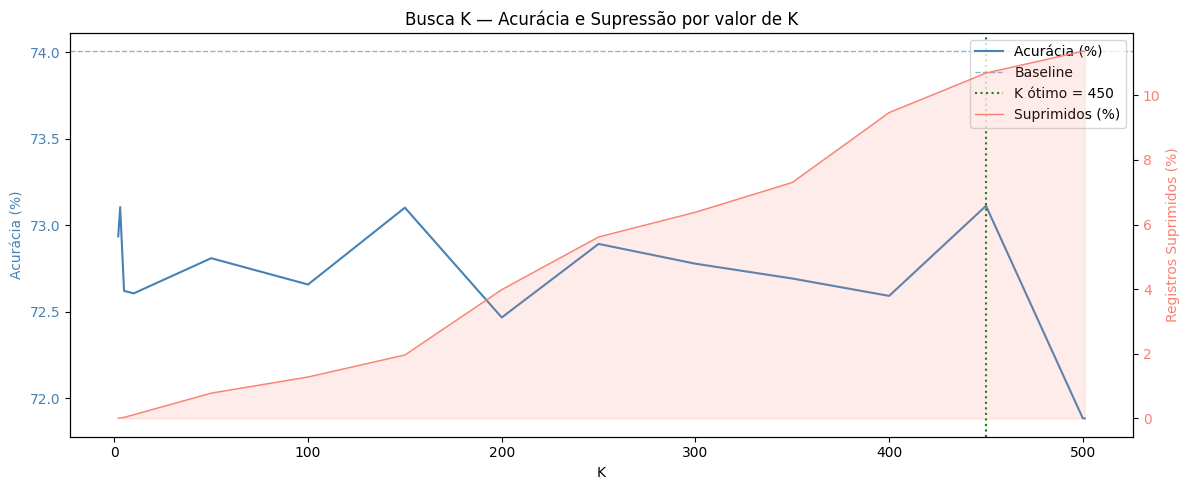

,k,acuracia,queda,registros_mantidos,suprimidos_pct
12,450,0.731126,0.008945,62517,10.69


In [49]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df_res_k['k'], df_res_k['acuracia'] * 100, color='steelblue', linewidth=1.5, label='Acurácia (%)')
ax1.axhline(acuracia_baseline * 100, color='steelblue', linestyle='--', linewidth=1, alpha=0.6, label='Baseline')
ax1.axvline(k_otimo, color='green', linestyle=':', linewidth=1.5, label=f'K ótimo = {k_otimo}')
ax1.set_xlabel('K')
ax1.set_ylabel('Acurácia (%)', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')

ax2 = ax1.twinx()
ax2.fill_between(df_res_k['k'], df_res_k['suprimidos_pct'], alpha=0.15, color='salmon')
ax2.plot(df_res_k['k'], df_res_k['suprimidos_pct'], color='salmon', linewidth=1, label='Suprimidos (%)')
ax2.set_ylabel('Registros Suprimidos (%)', color='salmon')
ax2.tick_params(axis='y', labelcolor='salmon')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.title('Busca K — Acurácia e Supressão por valor de K')
plt.tight_layout()
plt.show()

display(df_res_k[df_res_k['k'] == k_otimo][['k', 'acuracia', 'queda', 'registros_mantidos', 'suprimidos_pct']])


## Etapa 2: Busca pelo L ótimo (K_ótimo + L-Diversidade)

In [50]:
df_k_fixo = aplicar_k(df_base, k_otimo)

resultados_l = []

print(f"K fixo = {k_otimo}. Testando L de {min(L_RANGE)} a {max(L_RANGE)}...")

for l in L_RANGE:
    df_kl = aplicar_l(df_k_fixo, l)
    if len(df_kl) == 0:
        print(f"  L={l}: todos os registros suprimidos — interrompendo.")
        break
    acc = treinar_modelo(df_kl, QUASE_IDS + COLUNAS_MEDICAS)
    suprimidos_pct = 100.0 - (len(df_kl) * 100) / len(df_base)
    resultados_l.append({
        'l': l,
        'acuracia': acc,
        'queda': acuracia_baseline - acc,
        'registros_mantidos': len(df_kl),
        'suprimidos_pct': suprimidos_pct,
    })

df_res_l = pd.DataFrame(resultados_l)

l_otimo = df_res_l.loc[df_res_l['queda'].idxmin(), 'l']
l_otimo_acc = df_res_l.loc[df_res_l['queda'].idxmin(), 'acuracia']
l_otimo_queda = df_res_l.loc[df_res_l['queda'].idxmin(), 'queda']

print(f"\nL ótimo: l={l_otimo}")
print(f"  Acurácia: {l_otimo_acc*100:.2f}%  |  Queda: {l_otimo_queda*100:.2f} p.p.")
print(f"  Registros mantidos: {df_res_l.loc[df_res_l['l']==l_otimo, 'registros_mantidos'].values[0]}")

display(df_res_l)


K fixo = 450. Testando L de 2 a 5...

L ótimo: l=2
  Acurácia: 73.11%  |  Queda: 0.89 p.p.
  Registros mantidos: 62517


,l,acuracia,queda,registros_mantidos,suprimidos_pct
0,2,0.731126,0.008945,62517,10.69
1,3,0.731126,0.008945,62517,10.69
2,4,0.731126,0.008945,62517,10.69
3,5,0.731126,0.008945,62517,10.69


## Etapa 3: Busca pelo T ótimo (K_ótimo + T-Proximidade)

In [51]:
resultados_t_kt = []

print(f"K fixo = {k_otimo}. Testando T em {T_RANGE}...")

for t in T_RANGE:
    df_kt = aplicar_t(df_k_fixo, t)
    if len(df_kt) == 0:
        print(f"  T={t}: todos os registros suprimidos — interrompendo.")
        break
    acc = treinar_modelo(df_kt, QUASE_IDS + COLUNAS_MEDICAS)
    suprimidos_pct = 100.0 - (len(df_kt) * 100) / len(df_base)
    resultados_t_kt.append({
        't': t,
        'acuracia': acc,
        'queda': acuracia_baseline - acc,
        'registros_mantidos': len(df_kt),
        'suprimidos_pct': suprimidos_pct,
    })

df_res_t_kt = pd.DataFrame(resultados_t_kt)

t_otimo_kt = df_res_t_kt.loc[df_res_t_kt['queda'].idxmin(), 't']
t_otimo_kt_acc = df_res_t_kt.loc[df_res_t_kt['queda'].idxmin(), 'acuracia']
t_otimo_kt_queda = df_res_t_kt.loc[df_res_t_kt['queda'].idxmin(), 'queda']

print(f"\nT ótimo (K+T): t={t_otimo_kt}")
print(f"  Acurácia: {t_otimo_kt_acc*100:.2f}%  |  Queda: {t_otimo_kt_queda*100:.2f} p.p.")
print(f"  Registros mantidos: {df_res_t_kt.loc[df_res_t_kt['t']==t_otimo_kt, 'registros_mantidos'].values[0]}")

display(df_res_t_kt)


K fixo = 450. Testando T em [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]...

T ótimo (K+T): t=0.3
  Acurácia: 73.11%  |  Queda: 0.89 p.p.
  Registros mantidos: 62517


,t,acuracia,queda,registros_mantidos,suprimidos_pct
0,0.05,0.686674,0.053398,23823,65.967143
1,0.10,0.696368,0.043704,33725,51.821429
2,0.15,0.715772,0.024299,48059,31.344286
3,0.20,0.712913,0.027159,53590,23.442857
4,0.25,0.721070,0.019002,60015,14.264286
5,0.30,0.731126,0.008945,62517,10.690000
6,0.35,0.731126,0.008945,62517,10.690000
7,0.40,0.731126,0.008945,62517,10.690000
8,0.45,0.731126,0.008945,62517,10.690000
9,0.50,0.731126,0.008945,62517,10.690000


## Etapa 4: Busca pelo T ótimo (K_ótimo + L_ótimo + T-Proximidade)

In [52]:
df_kl_fixo = aplicar_l(df_k_fixo, l_otimo)

resultados_t_klt = []

print(f"K fixo = {k_otimo}, L fixo = {l_otimo}. Testando T em {T_RANGE}...")

for t in T_RANGE:
    df_klt = aplicar_t(df_kl_fixo, t)
    if len(df_klt) == 0:
        print(f"  T={t}: todos os registros suprimidos — interrompendo.")
        break
    acc = treinar_modelo(df_klt, QUASE_IDS + COLUNAS_MEDICAS)
    suprimidos_pct = 100.0 - (len(df_klt) * 100) / len(df_base)
    resultados_t_klt.append({
        't': t,
        'acuracia': acc,
        'queda': acuracia_baseline - acc,
        'registros_mantidos': len(df_klt),
        'suprimidos_pct': suprimidos_pct,
    })

df_res_t_klt = pd.DataFrame(resultados_t_klt)

t_otimo_klt = df_res_t_klt.loc[df_res_t_klt['queda'].idxmin(), 't']
t_otimo_klt_acc = df_res_t_klt.loc[df_res_t_klt['queda'].idxmin(), 'acuracia']
t_otimo_klt_queda = df_res_t_klt.loc[df_res_t_klt['queda'].idxmin(), 'queda']

print(f"\nT ótimo (K+L+T): t={t_otimo_klt}")
print(f"  Acurácia: {t_otimo_klt_acc*100:.2f}%  |  Queda: {t_otimo_klt_queda*100:.2f} p.p.")
print(f"  Registros mantidos: {df_res_t_klt.loc[df_res_t_klt['t']==t_otimo_klt, 'registros_mantidos'].values[0]}")

display(df_res_t_klt)


K fixo = 450, L fixo = 2. Testando T em [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]...

T ótimo (K+L+T): t=0.3
  Acurácia: 73.11%  |  Queda: 0.89 p.p.
  Registros mantidos: 62517


,t,acuracia,queda,registros_mantidos,suprimidos_pct
0,0.05,0.686674,0.053398,23823,65.967143
1,0.10,0.696368,0.043704,33725,51.821429
2,0.15,0.715772,0.024299,48059,31.344286
3,0.20,0.712913,0.027159,53590,23.442857
4,0.25,0.721070,0.019002,60015,14.264286
5,0.30,0.731126,0.008945,62517,10.690000
6,0.35,0.731126,0.008945,62517,10.690000
7,0.40,0.731126,0.008945,62517,10.690000
8,0.45,0.731126,0.008945,62517,10.690000
9,0.50,0.731126,0.008945,62517,10.690000


## Relatório Final

In [53]:
print("=" * 65)
print(" PoC1 - PARÂMETROS ÓTIMOS DE ANONIMIZAÇÃO")
print("=" * 65)
print(f"Acurácia Baseline (sem anonimização): {acuracia_baseline*100:.2f}%")
print("-" * 65)

configs = [
    ("Somente K",   f"K={k_otimo}",                           k_otimo_acc,    k_otimo_queda),
    ("K + L",       f"K={k_otimo} + L={l_otimo}",             l_otimo_acc,    l_otimo_queda),
    ("K + T",       f"K={k_otimo} + T={t_otimo_kt}",          t_otimo_kt_acc, t_otimo_kt_queda),
    ("K + L + T",   f"K={k_otimo} + L={l_otimo} + T={t_otimo_klt}", t_otimo_klt_acc, t_otimo_klt_queda),
]

for nome, params, acc, queda in configs:
    print(f"[{nome}]  {params}")
    print(f"  Acurácia: {acc*100:.2f}%  |  Queda: {queda*100:.2f} p.p.")
    print()

print("=" * 65)
print("Parâmetros recomendados para poc1.ipynb (menor queda total):")
melhor = min(configs, key=lambda x: x[3])
print(f"  {melhor[0]}: {melhor[1]}")
print(f"  Acurácia: {melhor[2]*100:.2f}%  |  Queda: {melhor[3]*100:.2f} p.p.")
print("=" * 65)


 PoC1 - PARÂMETROS ÓTIMOS DE ANONIMIZAÇÃO
Acurácia Baseline (sem anonimização): 74.01%
-----------------------------------------------------------------
[Somente K]  K=450
  Acurácia: 73.11%  |  Queda: 0.89 p.p.

[K + L]  K=450 + L=2
  Acurácia: 73.11%  |  Queda: 0.89 p.p.

[K + T]  K=450 + T=0.3
  Acurácia: 73.11%  |  Queda: 0.89 p.p.

[K + L + T]  K=450 + L=2 + T=0.3
  Acurácia: 73.11%  |  Queda: 0.89 p.p.

Parâmetros recomendados para poc1.ipynb (menor queda total):
  Somente K: K=450
  Acurácia: 73.11%  |  Queda: 0.89 p.p.
